<a href="https://colab.research.google.com/github/victor836768/piv_chess/blob/main/notebooks/etapa1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from collections import Counter, defaultdict
import csv
import json
import os
import random
import base64
from google.colab import drive


#ens connectem al drive
drive.mount('/content/drive/')

# Definim les rutes base per tenir-les a mà
drive_path = '/content/drive/MyDrive/PIV PROJECT V2'
data_zip = f'{drive_path}/data/raw/Dataset.v2i.coco.zip'
models_dir = f'{drive_path}/models'
!unzip -q "{data_zip}" -d /content/local_data
resultats_dir = f'{drive_path}/resultats'

# Baixem el codi del repo dins de la màquina virtual de Colab
!git clone https://github.com/victor836768/piv_chess
%cd piv_chess

Mounted at /content/drive/
Cloning into 'piv_chess'...
remote: Enumerating objects: 26, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 26 (delta 3), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (26/26), 7.22 KiB | 2.41 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/piv_chess


1. Fitxer JSON carregat correctament des de local!
2. ===============================================
  MAPEIG DE CLASSES DE PECES   
  Classe  0 -> black-bishop
  Classe  1 -> black-king
  Classe  2 -> black-knight
  Classe  3 -> black-pawn
  Classe  4 -> black-queen
  Classe  5 -> black-rook
  Classe  6 -> white-bishop
  Classe  7 -> white-king
  Classe  8 -> white-knight
  Classe  9 -> white-pawn
  Classe 10 -> white-queen
  Classe 11 -> white-rook

3. ===============================================
  RESUM DE LES IMATGES
Total d'imatges al JSON: 2077
Total de grups Gxxx detectats: 20

Desglossament d'imatges per grup:
  - Grup G000: 103 imatges
  - Grup G006: 120 imatges
  - Grup G019: 108 imatges
  - Grup G022: 108 imatges
  - Grup G028: 107 imatges
  - Grup G033: 103 imatges
  - Grup G038: 108 imatges
  - Grup G041: 102 imatges
  - Grup G042: 95 imatges
  - Grup G047: 108 imatges
  - Grup G056: 104 imatges
  - Grup G058: 101 imatges
  - Grup G061: 103 imatges
  - Grup G072: 101 i

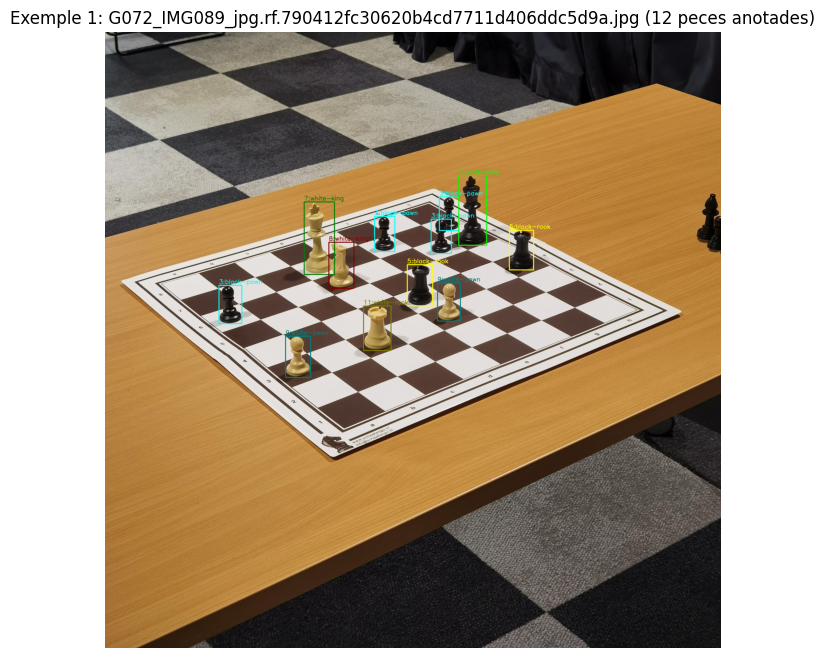

 - Exemple 2 (G061_IMG098_jpg.rf.dda45cb89591a09cd1e0d5805458f78c.jpg) afegit a l'HTML amb 13 peces.


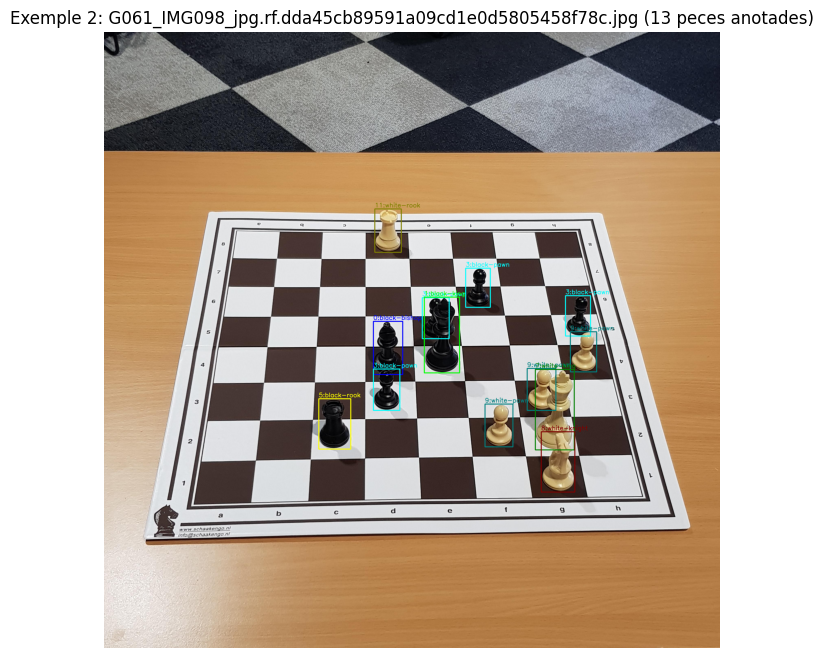

 - Exemple 3 (G028_IMG089_jpg.rf.dc3dc223b5ef066efffaebd7741a718b.jpg) afegit a l'HTML amb 17 peces.


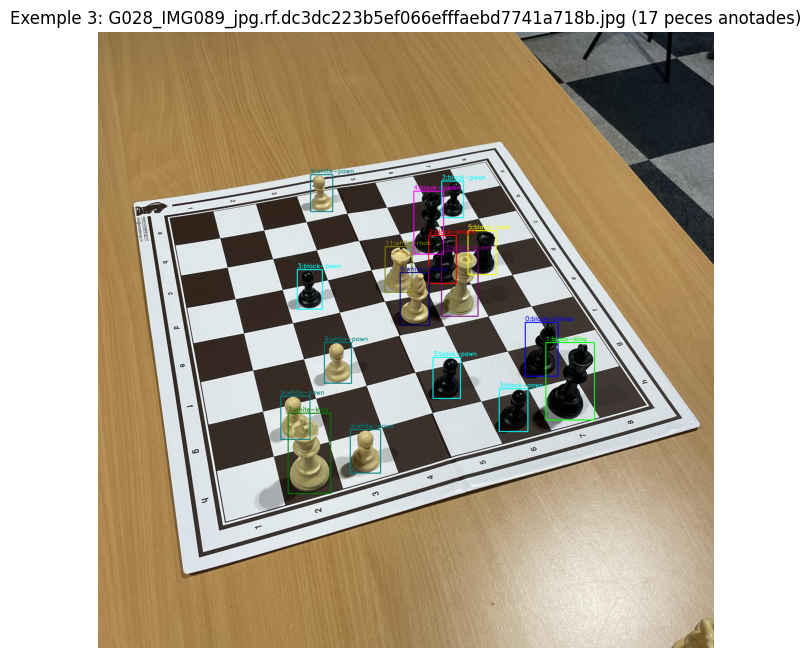

In [12]:
VERSIO = "v1"
linies_informe = []
imatges_informe = []
def registrar(text=""):
  print(text)
  linies_informe.append(text)

# 1. CARREGAR EL FITXER COCO JSON

json_path = "/content/local_data/train/_annotations.coco.json"
csv_out_path = os.path.join(drive_path, f"particions_manifest_{VERSIO}.csv")
html_out_path= os.path.join(resultats_dir, f"resum_dades_informe_{VERSIO}.html")

if not os.path.exists(json_path):
  registrar(f"ERROR: No s'ha trobat el fitxer '{json_path}'. Canvia la ruta.")
else:
  with open(json_path, "r", encoding="utf-8") as f:
    coco_data = json.load(f)
  registrar("1. Fitxer JSON carregat correctament des de local!")

# 2. MAPEIG DE CLASSES (0 -> 11)

categories = coco_data["categories"]

  # Excloem la categoria ID 0 buida
active_categories = [cat for cat in categories if cat["id"] != 0]

cat_id_to_label = {}
label_to_name = {}

  # Ordenem
for idx, cat in enumerate(sorted(active_categories, key=lambda x: x["id"])):
  cat_id_to_label[cat["id"]] = idx
  label_to_name[idx] = cat["name"]

registrar("2. ===============================================")
registrar("  MAPEIG DE CLASSES DE PECES   ")
registrar("==================================================")
for label, name in label_to_name.items():
  registrar(f"  Classe {label:2d} -> {name}")

# 3. AGRUPACIÓ D'IMATGES PER GRUP Gxxx

images = coco_data["images"]
group_to_images = defaultdict(list)

for img in images:
  filename = img["file_name"]
  group_prefix = filename.split("_")[0]
  group_to_images[group_prefix].append(img)

registrar("\n3. ===============================================")
registrar("  RESUM DE LES IMATGES")
registrar("==================================================")
registrar(f"Total d'imatges al JSON: {len(images)}")
registrar(f"Total de grups Gxxx detectats: {len(group_to_images)}")
registrar("\nDesglossament d'imatges per grup:")
for group_name, img_list in sorted(group_to_images.items()):
  registrar(f"  - Grup {group_name}: {len(img_list)} imatges")

# 4. RECOMPTE D'ANOTACIONS

annotations = coco_data.get("annotations", [])
valid_annotations = [
    ann for ann in annotations if ann["category_id"] in cat_id_to_label
  ]

registrar("\n4. ===============================================")
registrar("  RESUM D'ANOTACIONS")
registrar("==================================================")
registrar(f"Total de caixes/peces anotades vàlides: {len(valid_annotations)}")

# 5. SEGONA VERSIÓ D'ETIQUETES

DETECTOR_LABEL = 0
DETECTOR_NAME = "peça"

registrar("\n5. ===============================================")
registrar(" MAPEIG PER AL DETECTOR ")
registrar("==================================================")
registrar(
    f" Totes les caixes anotades -> Classe {DETECTOR_LABEL}:"
    f" '{DETECTOR_NAME}'"
  )

# 6. PARTICIONS PER GRUPS | 14 ENTRENAMENT  3 VALIDACIÓ  3 TEST

SEED = 9
random.seed(SEED)

llista_grups = sorted(list(group_to_images.keys()))
random.shuffle(llista_grups)

# Assignació
train_groups = set(llista_grups[:14])
val_groups = set(llista_grups[14:17])
test_groups = set(llista_grups[17:20])

group_to_split = {}
for g in train_groups:
  group_to_split[g] = "train"
for g in val_groups:
  group_to_split[g] = "val"
for g in test_groups:
  group_to_split[g] = "test"

# Generem les files del manifest i comptem imatges per partició
filas_manifest = []
img_id_to_split = {}
split_img_counts = defaultdict(int)

for img in images:
  filename = img["file_name"]
  group_prefix = filename.split("_")[0]
  split = group_to_split[group_prefix]
  img_id_to_split[img["id"]] = split
  filas_manifest.append(
      {"file_name": filename, "group": group_prefix, "split": split}
   )
  split_img_counts[split] += 1

# Guardar el fitxer particions_manifest.csv al Drive
with open(csv_out_path, "w", newline="", encoding="utf-8") as f:
  writer = csv.DictWriter(f, fieldnames=["file_name", "group", "split"])
  writer.writeheader()
  writer.writerows(filas_manifest)

registrar("\n6. ===============================================")
registrar(" PARTICIONS I GENERACIÓ DEL MANIFEST CSV")
registrar("==================================================")
registrar(f" Fitxer desat a: {csv_out_path}")
registrar(f" Total imatges al manifest: {len(filas_manifest)}")
registrar(
    f" - Train ({len(train_groups)} grups): {split_img_counts['train']}"
    " imatges"
)
registrar(
    f" - Val ({len(val_groups)} grups): {split_img_counts['val']} imatges"
)
registrar(
    f" - Test ({len(test_groups)} grups): {split_img_counts['test']} imatges"
)

# 7. VERIFICACIONS

classes_per_split = defaultdict(set)
for ann in valid_annotations:
  split = img_id_to_split[ann["image_id"]]
  label = cat_id_to_label[ann["category_id"]]
  classes_per_split[split].add(label)

registrar("\n7.1 ==============================================")
registrar(" VERIFICACIÓ DE REPRESENTACIÓ DE CLASSES")
registrar("==================================================")
for split_name in ["train", "val", "test"]:
  num_classes = len(classes_per_split[split_name])
  registrar(
      f" - Partició '{split_name}': {num_classes}/12 classes vàlides"
      " representades"
  )

# Recumpte de peces per classe
cat_counts = Counter(
    cat_id_to_label[ann["category_id"]] for ann in valid_annotations
)
total_piezas = len(valid_annotations)

registrar("\n7.2 ==============================================")
registrar(" DESGLOSSAMENT DE PECES PER TIPUS (CLASSIFICADOR)")
registrar("==================================================")
for lbl in range(12):
  nombre_pieza = label_to_name[lbl]
  cant = cat_counts[lbl]
  pct = (cant / total_piezas) * 100 if total_piezas > 0 else 0
  registrar(
      f" Classe {lbl:2d} ({nombre_pieza:15s}): {cant:5d} peces ({pct:5.2f}%)"
  )

# Estadístiques generals
total_imagenes = len(images)
media_piezas = total_piezas / total_imagenes if total_imagenes > 0 else 0

registrar("\n7.3 ==============================================")
registrar(" ESTADÍSTIQUES GENERALS DE L'ETAPA 1")
registrar("==================================================")
registrar(f" - Total peces anotades: {total_piezas}")
registrar(f" - Mitjana de peces per imatge: {media_piezas:.2f} peces/foto")

# 8. VISUALITZACIÓ D'EXEMPLES AMB CAIXES

import cv2 as cv
import matplotlib.pyplot as plt

# Ruta de la carpeta
ruta_carpeta_imagenes = "/content/local_data/train"

# Crear un mapa imagen_id -> anotacions
img_id_to_anns = defaultdict(list)
for ann in valid_annotations:
  img_id_to_anns[ann["image_id"]].append(ann)

# Buscar imagtges del disc
imagenes_encontradas = []
for img in images:
  path_img = os.path.join(ruta_carpeta_imagenes, img["file_name"])
  if os.path.exists(path_img):
    imagenes_encontradas.append(img)
    if len(imagenes_encontradas) == 3:  # Cogeremos hasta 3 imágenes de ejemplo
      break

registrar("\n8. ===============================================")
registrar("   GENERACIÓ D'IMATGES D'EXEMPLE CON CAJAS")
registrar("==================================================")

if not imagenes_encontradas:
  registrar(
      f"!! No s'han trobat imatges físiques a '{ruta_carpeta_imagenes}'."
      " Revisa la ruta."
  )
else:
  # Colors per cada peça
  colores = [
      (255, 0, 0),
      (0, 255, 0),
      (0, 0, 255),
      (255, 255, 0),
      (255, 0, 255),
      (0, 255, 255),
      (128, 0, 0),
      (0, 128, 0),
      (0, 0, 128),
      (128, 128, 0),
      (128, 0, 128),
      (0, 128, 128),
  ]

for idx, img_info in enumerate(imagenes_encontradas, start=1):
  path_img = os.path.join(ruta_carpeta_imagenes, img_info["file_name"])
  # Cargar la imagen con OpenCV
  img_bgr = cv.imread(path_img)
  if img_bgr is None:
    continue

  # DIBUIXAR CAIXES
  anns = img_id_to_anns[img_info["id"]]
  for ann in anns:
    cat_id = ann["category_id"]
    label = cat_id_to_label[cat_id]
    nombre_clase = label_to_name[label]

    # Format
    x, y, w, h = [int(v) for v in ann["bbox"]]
    color = colores[label % len(colores)]

    # Dibuixar rectangle
    cv.rectangle(img_bgr, (x, y), (x + w, y + h), color, 3)

    # Escribir la etiqueta de la clase encima del rectángulo
    txt = f"{label}:{nombre_clase}"
    cv.putText(
        img_bgr,
        txt,
        (x, max(y - 8, 15)),
        cv.FONT_HERSHEY_SIMPLEX,
        1,
        color,
        2,
    )

  _, buffer = cv.imencode(".png", img_bgr)
  img_base64 = base64.b64encode(buffer).decode("utf-8")

  imatges_informe.append(
      f"<h3>Exemple {idx}: {img_info['file_name']} ({len(anns)} peces"
      " anotades)</h3>"
      f"<img src='data:image/png;base64,{img_base64}' style='max-width:800px;"
      " border:1px solid #ccc; margin-bottom:20px;'><br>"
  )
  registrar(
      f" - Exemple {idx} ({img_info['file_name']}) afegit a l'HTML amb"
      f" {len(anns)} peces."
  )

    # Convertir de BGR (OpenCV) a RGB (Matplotlib/visualización)
  img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

  # Guardar la imagen procesada como figura para el informe
  #nombre_salida = os.path.join(
   #   resultats_dir, f"ejemplo_anotaciones_{VERSIO}_{idx}.png"
 #)
  #cv.imwrite(nombre_salida, img_bgr)
  #registrar(
   # f" - Guardada '{nombre_salida}' con {len(anns)} piezas dibujadas."
  #)

      # Mostrar la figura por pantalla
  plt.figure(figsize=(10, 8))
  plt.imshow(img_rgb)
  plt.title(
    f"Exemple {idx}: {img_info['file_name']} ({len(anns)} peces anotades)"
  )
  plt.axis("off")
  plt.show()


In [14]:
with open(html_out_path, "w", encoding="utf-8") as f:
  f.write(
      "<html><head><meta charset='utf-8'></head><body"
      " style='font-family:sans-serif; padding:20px;'>\n"
  )
  f.write(
      "<pre style='background:#f4f4f4; padding:15px; border-radius:8px;"
      " font-size:14px;'>\n"
  )
  f.write("\n".join(linies_informe))
  f.write("\n</pre>\n<hr>\n")
  f.write("\n".join(imatges_informe))
  f.write("\n</body></html>")

print(f"✅ HTML desat correctament amb {len(imatges_informe)} imatges a: {html_out_path}")

✅ HTML desat correctament amb 3 imatges a: /content/drive/MyDrive/PIV PROJECT V2/resultats/resum_dades_informe_v1.html
